# EDA on Grape Differences

1. I will group by region for reds and whites
* compare two grapes that are similar in the same region
* compare two grapes that are different in the same region
* compare popular grapes in the same region

3. Inter-region comparasons
* compare one grape in the different regions


# Reading in the data

The dataset should already be cleaned and processed for our models. The dataset was split into a 70,15,15 train, val, and test.

In [78]:
import pandas as pd

data = pd.read_parquet('processed_reviews.parquet')

In [79]:
data = data.drop(columns=['style_group', 'batch'])
data = data[data['is_blend'].eq(False)]

In [80]:
data.shape

(136470, 30)

In [96]:
data.head()

,review_id,grape,in_target,split,label_type,is_blend,color,category,description,description_masked,...,price,taster_name,taster_twitter_handle,source,source_row,reviewed,tokens_raw,tokens,clean_text,clean_designation
1,2,Portuguese Red,True,test,regional,False,red,still,"This is ripe and fruity, a wine that is smooth...","This is ripe and fruity, a wine that is smooth...",...,15.0,Roger Voss,@vossroger,130k,1,True,"[ripe, fruity, wine, smooth, still, structured...","[ripe, fruity, smooth, still, structured, firm...",ripe fruity smooth still structured firm tanni...,avidagos
2,3,Pinot Gris,True,train,grape,False,white,still,"Tart and snappy, the flavors of lime flesh and...","Tart and snappy, the flavors of lime flesh and...",...,14.0,Paul Gregutt,@paulgwine,130k,2,True,"[tart, snappy, flavor, lime, flesh, rind, domi...","[tart, snappy, lime, flesh, rind, dominate, gr...",tart snappy lime flesh rind dominate green pin...,
3,4,Riesling,True,train,grape,False,white,still,"Pineapple rind, lemon pith and orange blossom ...","Pineapple rind, lemon pith and orange blossom ...",...,13.0,Alexander Peartree,None,130k,3,True,"[pineapple, rind, lemon, pith, orange, blossom...","[pineapple, rind, lemon, pith, orange, blossom...",pineapple rind lemon pith orange blossom start...,reserve late harvest
4,5,Pinot Noir,True,train,grape,False,red,still,"Much like the regular bottling from 2012, this...","Much like the regular bottling from 2012, this...",...,65.0,Paul Gregutt,@paulgwine,130k,4,True,"[much, like, regular, bottling, come, across, ...","[much, like, regular, bottling, come, across, ...",much like regular bottling come across rather ...,vintner reserve wild child block
6,7,Frappato,False,train,grape,False,red,still,"Here's a bright, informal red that opens with ...","Here's a bright, informal red that opens with ...",...,16.0,Kerin O’Keefe,@kerinokeefe,130k,6,True,"[bright, informal, red, open, aroma, candied, ...","[bright, informal, red, open, candied, berry, ...",bright informal red open candied berry white p...,belsito


In [84]:
data.column

Index(['review_id', 'grape', 'in_target', 'split', 'label_type', 'is_blend',
       'color', 'category', 'description', 'description_masked', 'word_count',
       'variety', 'country', 'province', 'region_1', 'region_2', 'winery',
       'designation', 'title', 'points', 'price', 'taster_name',
       'taster_twitter_handle', 'source', 'source_row', 'reviewed',
       'tokens_raw', 'tokens', 'clean_text', 'clean_designation'],
      dtype='object')

In [207]:
province = data[data['country'] == 'US'].groupby('province').size()
province[province > 1000].sort_values(ascending=False)

,0
province,
California,43012
Washington,8548
Oregon,5810
New York,2763


In [176]:
data_red = data[data['color'] == 'red']
data_white = data[data['color'] == 'white']

In [180]:
data_red_california = data_red[data_red['province'].str.contains('California', case=False, na=False)]
data_white_california = data_white[data_white['province'].str.contains('California', case=False, na=False)]

In [182]:
data_red_california.groupby('grape').size().sort_values(ascending=False).head(10)

,0
grape,
Pinot Noir,8895
Cabernet Sauvignon,7917
Zinfandel,3803
Syrah,2768
Merlot,2156
Petite Sirah,915
Cabernet Franc,473
Grenache,439
Sangiovese,359


# CALIFORNIA

# Distinct Reds

In [198]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# We filter by grape and province to ensure we get the right regional pairs
mask = (
    ((data['grape'] == 'Syrah') & (data['province'].str.contains('California', case=False, na=False))) |
    ((data['grape'] == 'Pinot Noir') & (data['province'].str.contains('California', case=False, na=False)))
)

df_subset = data[mask].copy()

print("Subset class counts:")
print(df_subset.groupby(['grape', 'province']).size())

train_df = df_subset[df_subset['split'] == 'train']
val_df = df_subset[df_subset['split'] == 'val']

X_train = train_df['clean_text']
y_train = train_df['grape']

X_test = val_df['description_masked']
y_val = val_df['grape']

# 4. Vectorize text using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# 5. Train a Logistic Regression Classifier
model = LogisticRegression(max_iter=1000, random_state=4401)
model.fit(X_train_vec, y_train)

# 6. Evaluate the Model
y_pred = model.predict(X_test_vec)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_val, y_pred))

# 7. Extract Feature Importances (What makes them different?)
feature_names = vectorizer.get_feature_names_out()
classes = model.classes_

print(f"\nTop predictive words for {classes}:")

for i, class_name in enumerate(classes):
    coefs = model.coef_[0] if i == 1 else -model.coef_[0]
    top_word_indices = coefs.argsort()[-10:][::-1]
    top_words = [feature_names[j] for j in top_word_indices]
    print(f"  - {class_name}: {top_words}")

Subset class counts:
grape       province  
Pinot Noir  California    8895
Syrah       California    2768
dtype: int64

Accuracy: 0.9049

Classification Report:
              precision    recall  f1-score   support

  Pinot Noir       0.90      0.98      0.94      1301
       Syrah       0.91      0.64      0.75       382

    accuracy                           0.90      1683
   macro avg       0.91      0.81      0.85      1683
weighted avg       0.91      0.90      0.90      1683


Top predictive words for ['Pinot Noir' 'Syrah']:
  - Pinot Noir: ['cherry', 'silky', 'cola', 'raspberry', 'cranberry', 'pomegranate', 'tea', 'strawberry', 'heavy', 'rhubarb']
  - Syrah: ['blackberry', 'pepper', 'chocolate', 'leather', 'blueberry', 'meat', 'peppery', 'cassis', 'meaty', 'tannin']


# Similar Reds

In [200]:
# We filter by grape and province to ensure we get the right regional pairs
mask2 = (
    ((data['grape'] == 'Zinfandel') & (data['province'].str.contains('California', case=False, na=False))) |
    ((data['grape'] == 'Syrah') & (data['province'].str.contains('California', case=False, na=False)))
)

df_subset = data[mask2].copy()

print("Subset class counts:")
print(df_subset.groupby(['grape', 'province']).size())

train_df = df_subset[df_subset['split'] == 'train']
val_df = df_subset[df_subset['split'] == 'val']

X_train = train_df['clean_text']
y_train = train_df['grape']

X_test = val_df['description_masked']
y_val = val_df['grape']

# 4. Vectorize text using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# 5. Train a Logistic Regression Classifier
model = LogisticRegression(max_iter=1000, random_state=4401)
model.fit(X_train_vec, y_train)

# 6. Evaluate the Model
y_pred = model.predict(X_test_vec)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_val, y_pred))

# 7. Extract Feature Importances (What makes them different?)
feature_names = vectorizer.get_feature_names_out()
classes = model.classes_

print(f"\nTop predictive words for {classes}:")

for i, class_name in enumerate(classes):
    coefs = model.coef_[0] if i == 1 else -model.coef_[0]
    top_word_indices = coefs.argsort()[-10:][::-1]
    top_words = [feature_names[j] for j in top_word_indices]
    print(f"  - {class_name}: {top_words}")

Subset class counts:
grape      province  
Syrah      California    2768
Zinfandel  California    3803
dtype: int64

Accuracy: 0.7729

Classification Report:
              precision    recall  f1-score   support

       Syrah       0.75      0.65      0.69       382
   Zinfandel       0.79      0.85      0.82       578

    accuracy                           0.77       960
   macro avg       0.77      0.75      0.76       960
weighted avg       0.77      0.77      0.77       960


Top predictive words for ['Syrah' 'Zinfandel']:
  - Syrah: ['violet', 'bacon', 'blackberry', 'pepper', 'santa', 'elderberry', 'purple', 'white', 'dark', 'meat']
  - Zinfandel: ['briary', 'berry', 'wild', 'barbecue', 'brambly', 'spice', 'old', 'alcohol', 'vine', 'raspberry']


# California Whites

In [191]:
data_white_california.groupby('grape').size().sort_values(ascending=False).head(10)

,0
grape,
Chardonnay,6934
Sauvignon Blanc,2589
Pinot Gris,677
Viognier,621
Riesling,390
Gewürztraminer,196
Muscat,183
Albariño,114
Roussanne,111


# Distinct whites

In [194]:
# We filter by grape and province to ensure we get the right regional pairs
mask3 = (
    ((data['grape'] == 'Sauvignon Blanc') & (data['province'].str.contains('California', case=False, na=False))) |
    ((data['grape'] == 'Chardonnay') & (data['province'].str.contains('California', case=False, na=False)))
)

df_subset = data[mask3].copy()

print("Subset class counts:")
print(df_subset.groupby(['grape', 'province']).size())

train_df = df_subset[df_subset['split'] == 'train']
val_df = df_subset[df_subset['split'] == 'val']

X_train = train_df['clean_text']
y_train = train_df['grape']

X_test = val_df['description_masked']
y_val = val_df['grape']

# 4. Vectorize text using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# 5. Train a Logistic Regression Classifier
model = LogisticRegression(max_iter=1000, random_state=4401)
model.fit(X_train_vec, y_train)

# 6. Evaluate the Model
y_pred = model.predict(X_test_vec)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_val, y_pred))

# 7. Extract Feature Importances (What makes them different?)
feature_names = vectorizer.get_feature_names_out()
classes = model.classes_

print(f"\nTop predictive words for {classes}:")

for i, class_name in enumerate(classes):
    coefs = model.coef_[0] if i == 1 else -model.coef_[0]
    top_word_indices = coefs.argsort()[-10:][::-1]
    top_words = [feature_names[j] for j in top_word_indices]
    print(f"  - {class_name}: {top_words}")

Subset class counts:
grape            province  
Chardonnay       California    6934
Sauvignon Blanc  California    2589
dtype: int64

Accuracy: 0.8713

Classification Report:
                 precision    recall  f1-score   support

     Chardonnay       0.87      0.96      0.92      1052
Sauvignon Blanc       0.87      0.63      0.73       401

       accuracy                           0.87      1453
      macro avg       0.87      0.80      0.82      1453
   weighted avg       0.87      0.87      0.86      1453


Top predictive words for ['Chardonnay' 'Sauvignon Blanc']:
  - Chardonnay: ['oak', 'apple', 'buttered', 'caramel', 'pear', 'pineapple', 'toast', 'oaky', 'cream', 'butter']
  - Sauvignon Blanc: ['gooseberry', 'grass', 'grapefruit', 'melon', 'grassy', 'fig', 'citrus', 'pepper', 'white', 'lime']


# Similar whites

In [196]:
# We filter by grape and province to ensure we get the right regional pairs
mask3 = (
    ((data['grape'] == 'Viognier') & (data['province'].str.contains('California', case=False, na=False))) |
    ((data['grape'] == 'Chardonnay') & (data['province'].str.contains('California', case=False, na=False)))
)

df_subset = data[mask3].copy()

print("Subset class counts:")
print(df_subset.groupby(['grape', 'province']).size())

train_df = df_subset[df_subset['split'] == 'train']
val_df = df_subset[df_subset['split'] == 'val']

X_train = train_df['clean_text']
y_train = train_df['grape']

X_test = val_df['description_masked']
y_val = val_df['grape']

# 4. Vectorize text using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# 5. Train a Logistic Regression Classifier
model = LogisticRegression(max_iter=1000, random_state=4401, class_weight='balanced')
model.fit(X_train_vec, y_train)

# 6. Evaluate the Model
y_pred = model.predict(X_test_vec)
print(f"\nAccuracy: {accuracy_score(y_val, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_val, y_pred))

# 7. Extract Feature Importances (What makes them different?)
feature_names = vectorizer.get_feature_names_out()
classes = model.classes_

print(f"\nTop predictive words for {classes}:")

for i, class_name in enumerate(classes):
    coefs = model.coef_[0] if i == 1 else -model.coef_[0]
    top_word_indices = coefs.argsort()[-10:][::-1]
    top_words = [feature_names[j] for j in top_word_indices]
    print(f"  - {class_name}: {top_words}")

Subset class counts:
grape       province  
Chardonnay  California    6934
Viognier    California     621
dtype: int64

Accuracy: 0.8972

Classification Report:
              precision    recall  f1-score   support

  Chardonnay       0.96      0.92      0.94      1052
    Viognier       0.38      0.58      0.46        86

    accuracy                           0.90      1138
   macro avg       0.67      0.75      0.70      1138
weighted avg       0.92      0.90      0.91      1138


Top predictive words for ['Chardonnay' 'Viognier']:
  - Chardonnay: ['oak', 'toast', 'caramel', 'apple', 'pineapple', 'year', 'buttered', 'oaky', 'vineyard', 'butter']
  - Viognier: ['honeysuckle', 'exotic', 'wildflower', 'honey', 'floral', 'flower', 'peach', 'variety', 'apricot', 'honeyed']


# Now looking at one province but most popular grapes

# RED

In [257]:
# 1. Define one grape and 3+ target provinces
target_prov = 'California'
target_grapes = ['Pinot Noir','Cabernet Sauvignon', 'Zinfandel', 'Syrah', 'Merlot']

# 2. Filter dataset
mask = (
    (data['province'] == target_prov) &
    (data['grape'].isin(target_grapes))
)

df_subset = data[mask].copy()

# 3. Train/Test split using 'province' as the multi-class target
X_train = df_subset[df_subset['split'] == 'train']['clean_text']
y_train = df_subset[df_subset['split'] == 'train']['grape']

X_test = df_subset[df_subset['split'] == 'val']['clean_text']
y_test = df_subset[df_subset['split'] == 'val']['grape']

In [258]:
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [262]:
model = LogisticRegression(max_iter=1000, random_state=4401, class_weight='balanced')
model.fit(X_train_vec, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=4401)

In [263]:
y_test_pred = model.predict(X_test_vec)
print(f"\nAccuracy: {accuracy_score(y_test, y_test_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_test_pred))


Accuracy: 0.6694

Classification Report:
                    precision    recall  f1-score   support

Cabernet Sauvignon       0.76      0.65      0.70      1206
            Merlot       0.30      0.51      0.38       320
        Pinot Noir       0.88      0.81      0.84      1301
             Syrah       0.43      0.51      0.47       382
         Zinfandel       0.60      0.59      0.60       578

          accuracy                           0.67      3787
         macro avg       0.59      0.61      0.60      3787
      weighted avg       0.71      0.67      0.68      3787



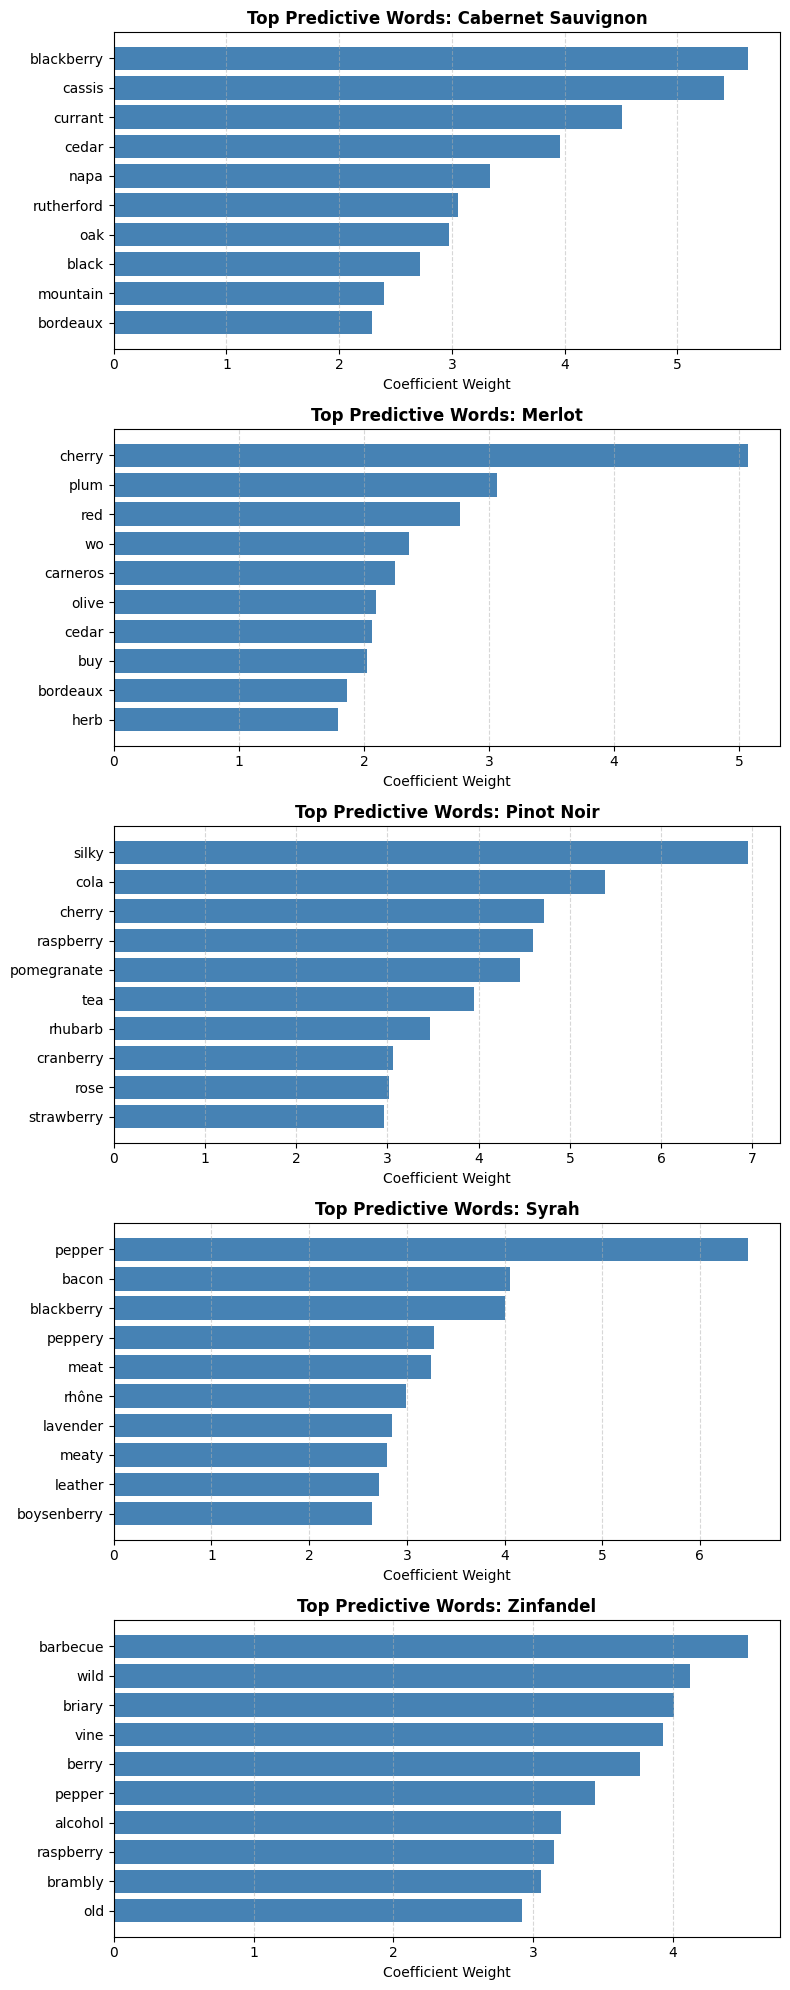

In [264]:
import matplotlib.pyplot as plt
import numpy as np

# Get feature names and classes
feature_names = vectorizer.get_feature_names_out()
classes = model.classes_
top_n = 10  # Number of top words to show per province

# Set up a subplot grid (one row per province)
fig, axes = plt.subplots(len(classes), 1, figsize=(8, 4 * len(classes)))

# Handle the edge case if axes is a single object (though multi-class has >= 3)
if len(classes) == 1:
    axes = [axes]

for i, class_name in enumerate(classes):
    ax = axes[i]
    coefs = model.coef_[i]

    # Get indices of the top N highest coefficients for this province
    top_indices = coefs.argsort()[-top_n:][::-1]
    top_words = [feature_names[j] for j in top_indices]
    top_coefs = coefs[top_indices]

    # Plot horizontal bar chart (reversed so the highest value is at the top)
    ax.barh(top_words[::-1], top_coefs[::-1], color='steelblue')
    ax.set_title(f'Top Predictive Words: {class_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Coefficient Weight', fontsize=10)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# WHITE

In [268]:
# 1. Define one grape and 3+ target provinces
target_prov = 'California'
target_grapes = ['Chardonnay','Sauvignon', 'Pinot Gris', 'Viognier']

# 2. Filter dataset
mask = (
    (data['province'] == target_prov) &
    (data['grape'].isin(target_grapes))
)

df_subset = data[mask].copy()

# 3. Train/Test split using 'province' as the multi-class target
X_train = df_subset[df_subset['split'] == 'train']['clean_text']
y_train = df_subset[df_subset['split'] == 'train']['grape']

X_test = df_subset[df_subset['split'] == 'val']['clean_text']
y_test = df_subset[df_subset['split'] == 'val']['grape']

In [269]:
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [270]:
model = LogisticRegression(max_iter=1000, random_state=4401, class_weight='balanced')
model.fit(X_train_vec, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=4401)

In [271]:
y_test_pred = model.predict(X_test_vec)
print(f"\nAccuracy: {accuracy_score(y_test, y_test_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_test_pred))


Accuracy: 0.7985

Classification Report:
              precision    recall  f1-score   support

  Chardonnay       0.95      0.84      0.89      1052
  Pinot Gris       0.38      0.61      0.47       103
    Viognier       0.30      0.53      0.39        86

    accuracy                           0.80      1241
   macro avg       0.55      0.66      0.58      1241
weighted avg       0.86      0.80      0.82      1241



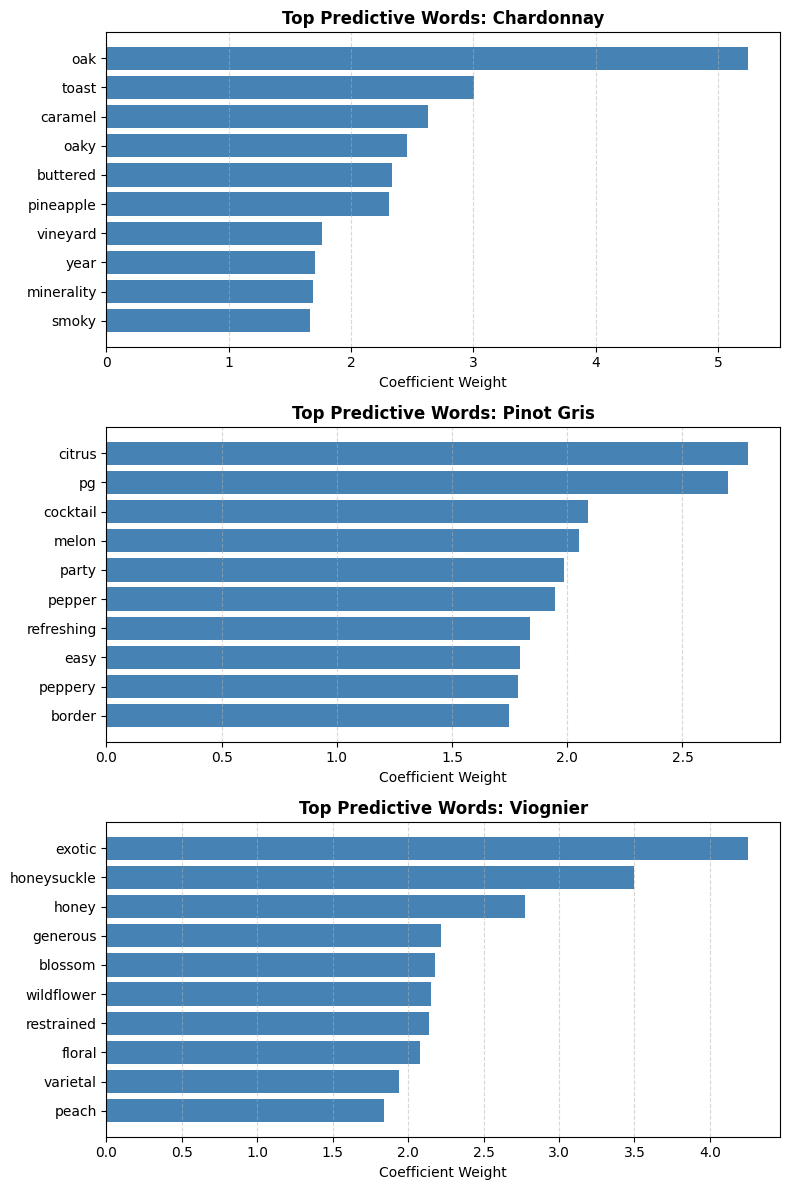

In [272]:
import matplotlib.pyplot as plt
import numpy as np

# Get feature names and classes
feature_names = vectorizer.get_feature_names_out()
classes = model.classes_
top_n = 10  # Number of top words to show per province

# Set up a subplot grid (one row per province)
fig, axes = plt.subplots(len(classes), 1, figsize=(8, 4 * len(classes)))

# Handle the edge case if axes is a single object (though multi-class has >= 3)
if len(classes) == 1:
    axes = [axes]

for i, class_name in enumerate(classes):
    ax = axes[i]
    coefs = model.coef_[i]

    # Get indices of the top N highest coefficients for this province
    top_indices = coefs.argsort()[-top_n:][::-1]
    top_words = [feature_names[j] for j in top_indices]
    top_coefs = coefs[top_indices]

    # Plot horizontal bar chart (reversed so the highest value is at the top)
    ax.barh(top_words[::-1], top_coefs[::-1], color='steelblue')
    ax.set_title(f'Top Predictive Words: {class_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Coefficient Weight', fontsize=10)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Now all provinces for one red grape

In [246]:
data_red_or = data_red[data_red['province'].str.contains('Oregon', case=False, na=False)]
data_white_or = data_white[data_white['province'].str.contains('Oregon', case=False, na=False)]

In [222]:
data_red_or.groupby('grape').size().sort_values(ascending=False).head(10)

,0
grape,
Pinot Noir,3190
Syrah,191
Tempranillo,101
Cabernet Sauvignon,90
Merlot,66
Cabernet Franc,48
Grenache,44
Malbec,38
Zinfandel,27


In [247]:
data_white_or.groupby('grape').size().sort_values(ascending=False).head(10)

,0
grape,
Pinot Gris,544
Chardonnay,542
Riesling,270
Pinot Blanc,128
Viognier,104
Gewürztraminer,62
Sauvignon Blanc,46
Grüner Veltliner,27
Muscat,18


In [241]:
# 1. Define one grape and 3+ target provinces
target_grape = 'Pinot Noir'
target_provinces = ['California','Oregon', 'New York']

# 2. Filter dataset
mask = (
    (data['grape'] == target_grape) &
    (data['province'].isin(target_provinces))
)

df_subset = data[mask].copy()

# 3. Train/Test split using 'province' as the multi-class target
X_train = df_subset[df_subset['split'] == 'train']['clean_text']
y_train = df_subset[df_subset['split'] == 'train']['province']

X_test = df_subset[df_subset['split'] == 'val']['clean_text']
y_test = df_subset[df_subset['split'] == 'val']['province']

In [242]:
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [243]:
model = LogisticRegression(max_iter=1000, random_state=4401, class_weight='balanced')
model.fit(X_train_vec, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=4401)

In [244]:
y_test_pred = model.predict(X_test_vec)
print(f"\nAccuracy: {accuracy_score(y_test, y_test_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_test_pred))


Accuracy: 0.9613

Classification Report:
              precision    recall  f1-score   support

  California       0.98      0.97      0.97      1301
    New York       0.83      0.95      0.89        21
      Oregon       0.93      0.94      0.94       513

    accuracy                           0.96      1835
   macro avg       0.91      0.95      0.93      1835
weighted avg       0.96      0.96      0.96      1835



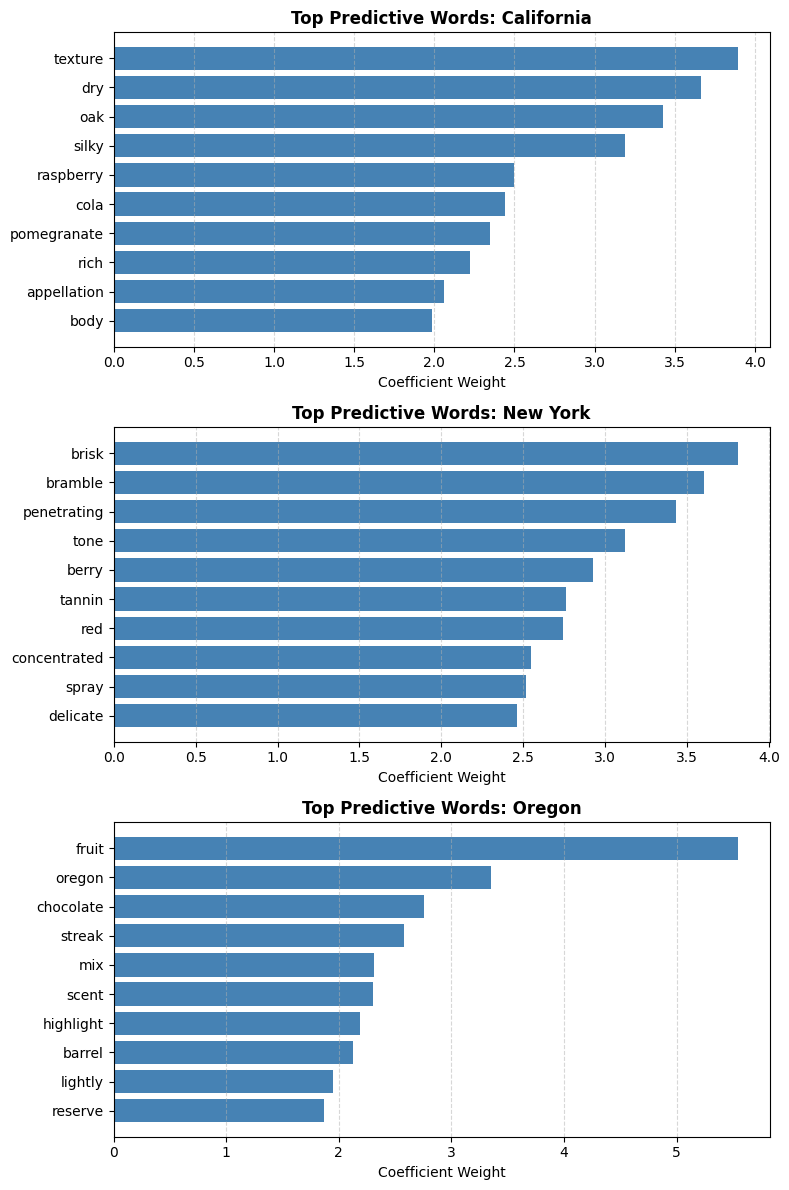

In [245]:
import matplotlib.pyplot as plt
import numpy as np

# Get feature names and classes
feature_names = vectorizer.get_feature_names_out()
classes = model.classes_
top_n = 10  # Number of top words to show per province

# Set up a subplot grid (one row per province)
fig, axes = plt.subplots(len(classes), 1, figsize=(8, 4 * len(classes)))

# Handle the edge case if axes is a single object (though multi-class has >= 3)
if len(classes) == 1:
    axes = [axes]

for i, class_name in enumerate(classes):
    ax = axes[i]
    coefs = model.coef_[i]

    # Get indices of the top N highest coefficients for this province
    top_indices = coefs.argsort()[-top_n:][::-1]
    top_words = [feature_names[j] for j in top_indices]
    top_coefs = coefs[top_indices]

    # Plot horizontal bar chart (reversed so the highest value is at the top)
    ax.barh(top_words[::-1], top_coefs[::-1], color='steelblue')
    ax.set_title(f'Top Predictive Words: {class_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Coefficient Weight', fontsize=10)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# FOR ONE WHITE GRAPE

In [248]:
# 1. Define one grape and 3+ target provinces
target_grape = 'Chardonnay'
target_provinces = ['California','Oregon', 'New York']

# 2. Filter dataset
mask = (
    (data['grape'] == target_grape) &
    (data['province'].isin(target_provinces))
)

df_subset = data[mask].copy()

# 3. Train/Test split using 'province' as the multi-class target
X_train = df_subset[df_subset['split'] == 'train']['clean_text']
y_train = df_subset[df_subset['split'] == 'train']['province']

X_test = df_subset[df_subset['split'] == 'val']['clean_text']
y_test = df_subset[df_subset['split'] == 'val']['province']

In [249]:
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [250]:
model = LogisticRegression(max_iter=1000, random_state=4401, class_weight='balanced')
model.fit(X_train_vec, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=4401)

In [251]:
y_test_pred = model.predict(X_test_vec)
print(f"\nAccuracy: {accuracy_score(y_test, y_test_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_test_pred))


Accuracy: 0.9454

Classification Report:
              precision    recall  f1-score   support

  California       0.98      0.96      0.97      1052
    New York       0.70      0.90      0.79        63
      Oregon       0.72      0.82      0.77        76

    accuracy                           0.95      1191
   macro avg       0.80      0.89      0.84      1191
weighted avg       0.95      0.95      0.95      1191



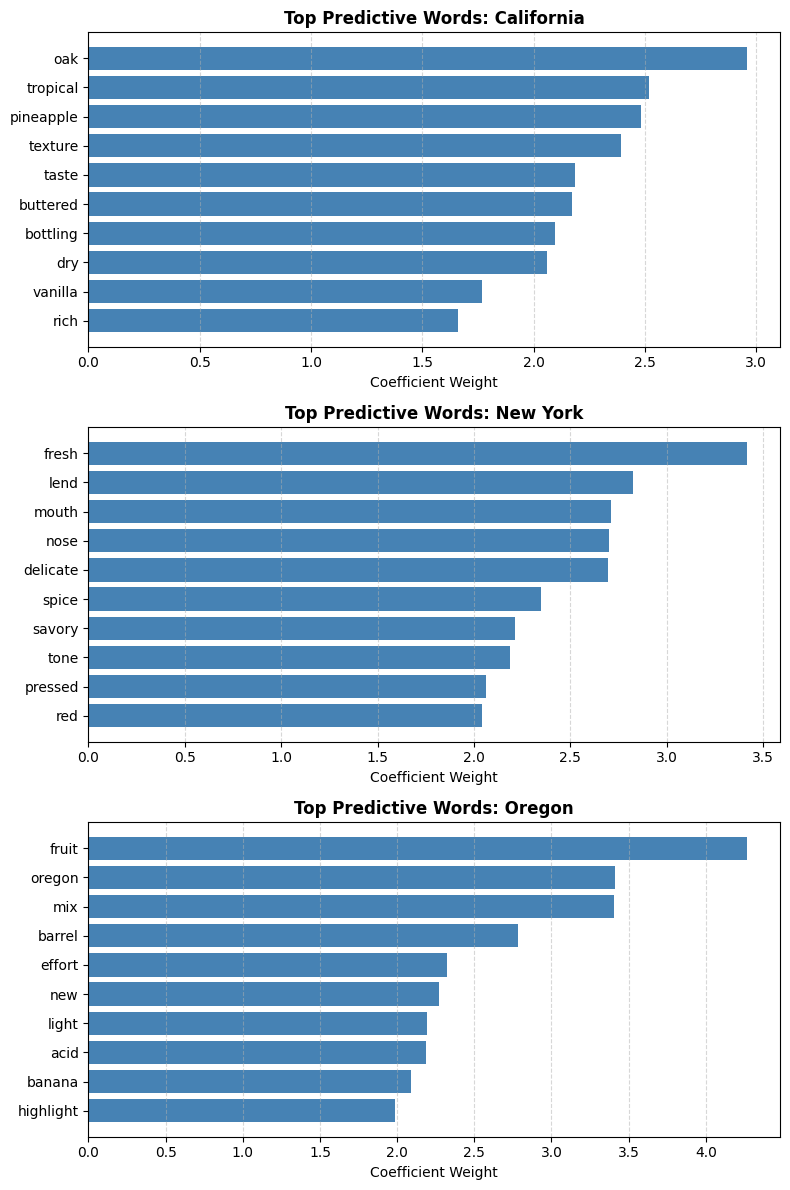

In [252]:
# Get feature names and classes
feature_names = vectorizer.get_feature_names_out()
classes = model.classes_
top_n = 10  # Number of top words to show per province

# Set up a subplot grid (one row per province)
fig, axes = plt.subplots(len(classes), 1, figsize=(8, 4 * len(classes)))

# Handle the edge case if axes is a single object (though multi-class has >= 3)
if len(classes) == 1:
    axes = [axes]

for i, class_name in enumerate(classes):
    ax = axes[i]
    coefs = model.coef_[i]

    # Get indices of the top N highest coefficients for this province
    top_indices = coefs.argsort()[-top_n:][::-1]
    top_words = [feature_names[j] for j in top_indices]
    top_coefs = coefs[top_indices]

    # Plot horizontal bar chart (reversed so the highest value is at the top)
    ax.barh(top_words[::-1], top_coefs[::-1], color='steelblue')
    ax.set_title(f'Top Predictive Words: {class_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Coefficient Weight', fontsize=10)
    ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()